<a href="https://colab.research.google.com/github/hombremono873/Cuadernos_colab/blob/main/House_Price.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis y Preprocesamiento de Datos — House Prices

Este cuaderno presenta primero todo el contexto conceptual del dataset y de las decisiones de preprocesamiento (origen, estructura, variables y estrategia de imputación), y luego el código, organizado en funciones agrupadas por objetivo y orquestadas desde un bloque `main()` al final.


## 1. Origen del Dataset

El dataset proviene de la competencia de Kaggle *House Prices: Advanced Regression Techniques*:

https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data

El archivo de trabajo es `train.csv`, cargado como un DataFrame de pandas.


## 2. Estructura General del Dataset

Según la descripción de variables (`data_description.txt` de la competencia), el dataset está compuesto por 81 columnas: un identificador (`Id`), 79 variables predictoras y la variable objetivo `SalePrice` (precio de venta). El número de filas y el tamaño exacto (`df.shape`) se obtienen al cargar el archivo.


## 3. Tipos de Predictores y Variables

Las variables del dataset se agrupan en tres tipos:

- **Numéricas**: variables continuas o discretas (áreas, años, cantidades), por ejemplo `LotArea`, `YearBuilt`, `GrLivArea`.
- **Categóricas nominales**: sin orden implícito entre sus categorías, por ejemplo `MSZoning`, `Neighborhood`, `SaleType`.
- **Categóricas ordinales**: con un orden implícito entre sus categorías (p. ej. de calidad), por ejemplo `ExterQual`, `KitchenQual`, `PoolQC`.

Esta clasificación es la base tanto para la estrategia de imputación de nulos como para la estrategia de codificación aplicadas más adelante.


## 4. Descripción de Variables del Dataset

Aquí tienes una versión resumida de lo que encontrarás en el archivo de descripción de datos.

1.  **Id** : Identificador único para cada casa.
2.  **MSSubClass** : Tipo de vivienda involucrada en la venta.
3.  **MSZoning** : Clasificación general de zonificación de la venta.
4.  **LotFrontage** : Pies lineales de la calle conectados a la propiedad.
5.  **LotArea** : Tamaño del lote en pies cuadrados.
6.  **Street** : Tipo de acceso por carretera a la propiedad.
7.  **Alley** : Tipo de acceso al callejón.
8.  **LotShape** : Forma general de la propiedad.
9.  **LandContour** : Nivelación de la propiedad.
10. **Utilities** : Tipo de servicios públicos disponibles.
11. **LotConfig** : Configuración del lote.
12. **LandSlope** : Pendiente de la propiedad.
13. **Neighborhood** : Ubicación física dentro de los límites de la ciudad de Ames.
14. **Condition1** : Proximidad a la carretera principal o ferrocarril.
15. **Condition2** : Proximidad a la carretera principal o ferrocarril (si hay una segunda).
16. **BldgType** : Tipo de vivienda.
17. **HouseStyle** : Estilo de la vivienda.
18. **OverallQual** : Calidad general del material y acabado (1-10).
19. **OverallCond** : Condición general de la vivienda (1-10).
20. **YearBuilt** : Año de construcción original.
21. **YearRemodAdd** : Año de remodelación (si no hay remodelación, el mismo que YearBuilt).
22. **RoofStyle** : Tipo de techo.
23. **RoofMatl** : Material del techo.
24. **Exterior1st** : Revestimiento exterior en la casa.
25. **Exterior2nd** : Revestimiento exterior secundario en la casa.
26. **MasVnrType** : Tipo de revestimiento de mampostería.
27. **MasVnrArea** : Área de revestimiento de mampostería en pies cuadrados.
28. **ExterQual** : Calidad del material exterior (Excelente, Bueno, etc.).
29. **ExterCond** : Condición actual del exterior (Excelente, Bueno, etc.).
30. **Foundation** : Tipo de cimentación.
31. **BsmtQual** : Altura del sótano.
32. **BsmtCond** : Condición general del sótano.
33. **BsmtExposure** : Exposición del sótano.
34. **BsmtFinType1** : Calificación del área terminada del sótano (tipo 1).
35. **BsmtFinSF1** : Pies cuadrados del área terminada del sótano (tipo 1).
36. **BsmtFinType2** : Calificación del área terminada del sótano (tipo 2).
37. **BsmtFinSF2** : Pies cuadrados del área sin terminar del sótano.
38. **BsmtUnfSF** : Pies cuadrados del área sin terminar del sótano.
39. **TotalBsmtSF** : Pies cuadrados totales del sótano.
40. **Heating** : Tipo de calefacción.
41. **HeatingQC** : Calidad y condición de la calefacción.
42. **CentralAir** : Aire acondicionado central.
43. **Electrical** : Sistema eléctrico.
44. **1stFlrSF** : Pies cuadrados del primer piso.
45. **2ndFlrSF** : Pies cuadrados del segundo piso.
46. **LowQualFinSF** : Pies cuadrados terminados de baja calidad (todos los pisos).
47. **GrLivArea** : Pies cuadrados del área habitable sobre el nivel del suelo.
48. **BsmtFullBath** : Baños completos en el sótano.
49. **BsmtHalfBath** : Medios baños en el sótano.
50. **FullBath** : Baños completos sobre el nivel del suelo.
51. **HalfBath** : Medios baños sobre el nivel del suelo.
52. **BedroomAbvGr** : Número de dormitorios sobre el nivel del suelo.
53. **KitchenAbvGr** : Número de cocinas sobre el nivel del suelo.
54. **KitchenQual** : Calidad de la cocina.
55. **TotRmsAbvGrd** : Total de habitaciones sobre el nivel del suelo (sin incluir baños).
56. **Functional** : Calificación de funcionalidad del hogar.
57. **Fireplaces** : Número de chimeneas.
58. **FireplaceQu** : Calidad de la chimenea.
59. **GarageType** : Ubicación del garaje.
60. **GarageYrBlt** : Año en que se construyó el garaje.
61. **GarageFinish** : Acabado interior del garaje.
62. **GarageCars** : Tamaño del garaje en capacidad de vehículos.
63. **GarageArea** : Tamaño del garaje en pies cuadrados.
64. **GarageQual** : Calidad del garaje.
65. **GarageCond** : Condición del garaje.
66. **PavedDrive** : Entrada pavimentada.
67. **WoodDeckSF** : Área de la cubierta de madera en pies cuadrados.
68. **OpenPorchSF** : Área del porche abierto en pies cuadrados.
69. **EnclosedPorch** : Área del porche cerrado en pies cuadrados.
70. **3SsnPorch** : Área del porche de tres estaciones en pies cuadrados.
71. **ScreenPorch** : Área del porche con mosquitero en pies cuadrados.
72. **PoolArea** : Área de la piscina en pies cuadrados.
73. **PoolQC** : Calidad de la piscina.
74. **Fence** : Calidad de la valla.
75. **MiscFeature** : Características misceláneas no cubiertas en otras categorías.
76. **MiscVal** : Valor de las características misceláneas.
77. **MoSold** : Mes de venta.
78. **YrSold** : Año de venta.
79. **SaleType** : Tipo de venta.
80. **SaleCondition** : Condición de la venta.
81. **SalePrice** : Precio de venta (variable objetivo).


## 5. Clasificación de Variables Categóricas y Numéricas

A continuación se presenta un análisis de las variables categóricas del dataset: para cada una se indica si es nominal u ordinal y el número de categorías que posee. La clasificación se basa en la descripción de variables de la sección anterior.

Las listas concretas de columnas —`nominal_cols`, `ordinal_cols` y `numerical_vars`— se centralizan en la función `obtener_configuracion_columnas()` de la sección de código, para evitar duplicarlas en distintas partes del cuaderno.


## 6. Estrategia de Tratamiento de Valores Nulos — House Prices Dataset

### Variables categóricas donde NaN = "no tiene esa característica"

**PoolQC** (99.52% nulo)
- **Acción:** Imputar con `"None"`.
- **Justificación:** Según `data_description.txt`, NaN indica que la casa no tiene piscina. Es coherente con que casi ninguna vivienda residencial tenga piscina — no es un dato perdido, es información real sobre la propiedad.

**MiscFeature** (96.3% nulo)
- **Acción:** Imputar con `"None"`.
- **Justificación:** NaN significa que la propiedad no tiene ninguna característica miscelánea (cancha de tenis, cobertizo, elevador, etc.). La ausencia es la categoría predominante y válida.

**Alley** (93.77% nulo)
- **Acción:** Imputar con `"None"`.
- **Justificación:** NaN indica que la propiedad no tiene acceso por callejón — la mayoría de casas efectivamente no lo tienen, por lo que el nulo es informativo, no faltante.

**Fence** (80.75% nulo)
- **Acción:** Imputar con `"None"`.
- **Justificación:** NaN indica ausencia de cerca perimetral. Igual que los casos anteriores, es una categoría legítima, no un vacío de información.

**MasVnrType** (59.73% nulo)
- **Acción:** Imputar con `"None"`.
- **Justificación:** Representa el tipo de revestimiento de mampostería (ladrillo, piedra, etc.). NaN indica que la casa no tiene revestimiento de este tipo — consistente con que `MasVnrArea` (área del revestimiento) también tenga nulos casi en la misma proporción cuando el valor es 0.

**FireplaceQu** (47.26% nulo)
- **Acción:** Imputar con `"None"`.
- **Justificación:** NaN indica que la casa no tiene chimenea. Es razonable que casi la mitad de las viviendas no tengan una — información real, no error de captura.

### Variables relacionadas a garaje (mismo patrón de ausencia)

**GarageType** (5.55% nulo) — categórica
- **Acción:** Imputar con `"None"`.
- **Justificación:** NaN indica que la casa no tiene garaje. El mismo porcentaje se repite consistentemente en las demás variables de garaje, confirmando que corresponden a las mismas filas (casas sin garaje).

**GarageYrBlt** (5.55% nulo) — numérica
- **Acción:** Imputar con `0`, o alternativamente con el valor de `YearBuilt` (año de construcción de la casa).
- **Justificación:** No existe un "año de construcción del garaje" si no hay garaje. La opción de imputar con `YearBuilt` es más segura numéricamente porque evita introducir un valor atípico extremo (año 0) que podría afectar la escala de la variable durante el entrenamiento.

**GarageFinish** (5.55% nulo) — categórica
- **Acción:** Imputar con `"None"`.
- **Justificación:** Mismo patrón — indica ausencia de garaje, coherente con `GarageType` nulo en las mismas filas.

**GarageQual** (5.55% nulo) — categórica
- **Acción:** Imputar con `"None"`.
- **Justificación:** Igual razonamiento — calidad del garaje no aplica si no existe garaje.

**GarageCond** (5.55% nulo) — categórica
- **Acción:** Imputar con `"None"`.
- **Justificación:** Igual razonamiento — condición del garaje no aplica si no existe garaje.

### Variables numéricas

Se imputan los valores nulos en las variables numéricas basándose en la media y la mediana, según las reglas:

1.  **Media y Mediana Similares:** Si `|Media - Mediana| < 2.0`, se imputa con la `Media`.
2.  **Mediana = 0 y Media > 0:** Si `Mediana == 0` y `Media > 0`, se imputa con la `Mediana` (es decir, con 0).

### Caso especial: 'Electrical'

`Electrical` es la única variable con nulos que no corresponde a una ausencia informativa de característica; se imputa con la moda.


## 7. Flujo de Preprocesamiento y Resultado Final

Resumen del flujo de codificación, escalado y preparación de los datos:

1. Separar variables en `df_ordinal`, `df_nominal`, `df_numerico`.
2. Codificar `df_ordinal` → Ordinal Encoding.
3. Codificar `df_nominal` → One-Hot Encoding.
4. Unir `df_ordinal` (ya codificado) + `df_numerico` → escalar juntos.
5. `df_final` = df_escalado (ordinal + numérico) + df_nominal (ya en 0/1, sin escalar).

Al finalizar el pipeline se obtienen las siguientes variables:

| Variable | Contenido |
|---|---|
| `X_train` | Predictoras de entrenamiento (codificadas + escaladas) |
| `X_test` | Predictoras de prueba (codificadas + escaladas, con parámetros de `X_train`) |
| `y_train_log` | Variable objetivo de entrenamiento, transformada con `log1p` |
| `y_test_log` | Variable objetivo de prueba, transformada con `log1p` |

---

## Sección de Código

El código se organiza en funciones agrupadas por objetivo (configuración, carga, análisis, limpieza, visualización, codificación y preparación para modelado), orquestadas desde una función `main()` al final del cuaderno.


In [1]:
!pip install keras

In [3]:
!pip install -q keras-tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 2.7 MB/s eta 0:00:00


In [15]:
# Importación de librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
import keras_tuner as kt


In [64]:
def obtener_configuracion_columnas():
    """
    Centraliza las listas de columnas usadas en las distintas etapas del pipeline.

    Retorna
    -------
    dict
        Diccionario con las listas de columnas: ordinales, nominales, numéricas,
        columnas a imputar con 'None' y columnas a escalar.
    """
    ordinal_cols = [
        'LotShape', 'Utilities', 'LandSlope', 'ExterQual', 'ExterCond', 'BsmtQual', 'BsmtCond',
        'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'HeatingQC', 'KitchenQual', 'Functional',
        'FireplaceQu', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence'
    ]  # Identificadas como con orden claro según data_description o sentido común

    nominal_cols = [
        'MSZoning', 'Street', 'Alley', 'LandContour', 'LotConfig', 'Neighborhood',
        'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl',
        'Exterior1st', 'Exterior2nd', 'MasVnrType', 'Foundation', 'Heating', 'CentralAir',
        'Electrical', 'GarageType', 'MiscFeature', 'SaleType', 'SaleCondition'
    ]

    numerical_vars = [
        'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt',
        'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF',
        '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath',
        'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces',
        'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch',
        '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold'
    ]

    cols_to_impute_with_none = [
        'PoolQC', 'MiscFeature', 'Alley', 'Fence', 'MasVnrType', 'FireplaceQu',
        'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond',
        'BsmtExposure', 'BsmtFinType2', 'BsmtQual', 'BsmtFinType1', 'BsmtCond'
    ]

    cols_a_escalar = numerical_vars + ordinal_cols

    return {
        'ordinal_cols': ordinal_cols,
        'nominal_cols': nominal_cols,
        'numerical_vars': numerical_vars,
        'cols_to_impute_with_none': cols_to_impute_with_none,
        'cols_a_escalar': cols_a_escalar,
    }


In [65]:
"""
    Carga el dataset de House Prices desde un archivo CSV.

    Parámetros
    ----------
    path : str
        Ruta del archivo CSV a cargar.

    Retorna
    -------
    pd.DataFrame
        DataFrame con los datos cargados.
"""
def cargar_dataset(path):
    file = pd.read_csv(path)
    df = pd.DataFrame(file)
    return df

"""
    Muestra una descripción general del dataset: contenido, dimensiones,
    tipos de datos y estadísticas descriptivas.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame a describir.

    Retorna
    -------
    None
"""
def describir_dataset(df):
   # display(df)
    #print(f"Tamaño {df.shape}")
    df.info()
   # display(df.describe())
    pass

"""
    Etapa 1 del pipeline: carga el dataset y muestra su descripción general.

    Parámetros
    ----------
    path : str
        Ruta del archivo CSV a cargar.

    Retorna
    -------
    pd.DataFrame
        DataFrame cargado.
 """
def cargar_y_describir_datos(path):
    df = cargar_dataset(path)
    describir_dataset(df)
    return df


In [67]:
"""
    Clasifica las columnas categóricas del DataFrame en nominales u ordinales
    y cuenta el número de categorías de cada una.
    Retorna un DataFrame con 'Variable', 'Tipo' y 'Número de Categorías'.
"""

def clasificar_variables_categoricas(df, ordinal_vars):
    categorical_cols = df.select_dtypes(include='object').columns
    categorical_info = []
    for col in categorical_cols:
        num_categories = df[col].nunique(dropna=False)
        col_type = 'Ordinal' if col in ordinal_vars else 'Nominal'
        categorical_info.append({'Variable': col, 'Tipo': col_type, 'Número de Categorías': num_categories})

    categorical_df = pd.DataFrame(categorical_info)
    categorical_df = categorical_df.sort_values(by=['Tipo', 'Variable']).reset_index(drop=True)
    return categorical_df


"""
    Calcula media, mediana, moda y porcentaje de nulos para cada variable numérica.
    Retorna un DataFrame con 'Variable', 'Media', 'Mediana', 'Moda' y '% Nulos'.
"""
def calcular_estadisticas_numericas(df, excluir_cols=('Id', 'SalePrice')):
    numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns
    numerical_cols = [col for col in numerical_cols if col not in excluir_cols]

    stats = []
    for col in numerical_cols:
        media_val = df[col].mean()
        mediana_val = df[col].median()
        mode_vals = df[col].mode()
        moda_val = mode_vals.iloc[0] if not mode_vals.empty else None
        pct_nulos = df[col].isna().mean() * 100

        stats.append({
            'Variable': col,
            'Media': round(media_val, 2),
            'Mediana': round(mediana_val, 2),
            'Moda': moda_val,
            '% Nulos': round(pct_nulos, 2)
        })

    stats_df = pd.DataFrame(stats)
    stats_df = stats_df.sort_values('% Nulos', ascending=False).reset_index(drop=True)
    return stats_df

"""
   Ejecuta el análisis exploratorio de variables categóricas y numéricas,
   mostrando las tablas resultantes.
   Retorna (categorical_df, stats_df).
"""
def analizar_variables(df, ordinal_vars):
    categorical_df = clasificar_variables_categoricas(df, ordinal_vars)
    display(categorical_df)

    ordinal_variables = categorical_df[categorical_df['Tipo'] == 'Ordinal']
    display(ordinal_variables)

    stats_df = calcular_estadisticas_numericas(df)
    display(stats_df)

    return categorical_df, stats_df

In [68]:
"""
    Imputa valores nulos en variables numéricas según reglas basadas en media y mediana:
    - Si |Media - Mediana| < 2.0, imputa con la Media.
    - Si Mediana == 0 y Media > 0, imputa con la Mediana (0).

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame a imputar (se modifica in-place).
    stats_df : pd.DataFrame
        Tabla de estadísticas generada por `calcular_estadisticas_numericas`.

    Retorna
    -------
    pd.DataFrame
        El mismo DataFrame `df`, con las variables numéricas imputadas.
"""
def imputar_numericas(df, stats_df):
   for _, row in stats_df.iterrows():
        variable = row['Variable']
        media = row['Media']
        mediana = row['Mediana']
        pct_nulos = row['% Nulos']

        if pct_nulos > 0:
            if abs(media - mediana) < 2.0:  # Umbral de 2.0 para 'similares'
                df[variable] = df[variable].fillna(media)
                print(f"Imputando '{variable}' con la Media ({media:.2f}) debido a media y mediana similares.")
            elif mediana == 0 and media > 0:
                df[variable] = df[variable].fillna(mediana)  # Mediana es 0 en este caso
                print(f"Imputando '{variable}' con la Mediana (0) debido a Mediana=0 y Media>0.")
            else:
                print(f"La variable '{variable}' tiene {pct_nulos:.2f}% nulos pero no cumple las condiciones de imputación especificadas. No se imputa en este paso.")
   return df

"""
    Imputa con la categoría 'None' las columnas categóricas donde un valor
    nulo representa la ausencia de esa característica.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame a imputar (se modifica in-place).
    cols_to_impute_with_none : list[str]
        Columnas categóricas a imputar con 'None'.

    Retorna
    -------
    pd.DataFrame
        El mismo DataFrame `df`, con las columnas indicadas imputadas.
"""
def imputar_categoricas_none(df, cols_to_impute_with_none):
    print("Columnas categóricas a imputar con 'None':")
    for col in cols_to_impute_with_none:
        if col in df.columns:
            initial_nulls = df[col].isnull().sum()
            if initial_nulls > 0:
                df[col] = df[col].fillna('None')
                print(f"  - '{col}': {initial_nulls} valores nulos imputados con 'None'.")
            else:
                print(f"  - '{col}': No tenía valores nulos para imputar.")
        else:
            print(f"  - '{col}': No encontrada en el DataFrame.")
    return df

"""
    Imputa los valores nulos de la columna 'Electrical' con su moda.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame a imputar (se modifica in-place).

    Retorna
    -------
    pd.DataFrame
        El mismo DataFrame `df`, con 'Electrical' imputada.
"""
def imputar_electrical_moda(df):
    if 'Electrical' in df.columns:
        electrical_mode = df['Electrical'].mode()[0]  # Obtener el primer modo si hay varios
        initial_electrical_nulls = df['Electrical'].isnull().sum()
        if initial_electrical_nulls > 0:
            df['Electrical'] = df['Electrical'].fillna(electrical_mode)
            print(f"Imputando '{initial_electrical_nulls}' valores nulos en la columna 'Electrical' con la moda '{electrical_mode}'.")
        else:
            print("La columna 'Electrical' no tenía valores nulos para imputar.")
    else:
        print("La columna 'Electrical' no se encuentra en el DataFrame.")
    return df

"""
    Reporta el porcentaje de valores nulos restantes por columna en el DataFrame.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame a verificar.
    titulo : str
        Título descriptivo para el reporte impreso.
    col_pendiente : str, opcional
        Si se indica y es la única columna con nulos restantes, se reporta
        aparte como pendiente de imputación manual, en vez de listarla en la tabla.

    Retorna
    -------
    pd.DataFrame or None
        Tabla con las columnas y su porcentaje de nulos restantes, o None si
        no quedan nulos (o si la única pendiente es `col_pendiente`).
"""
def verificar_nulos_restantes(df, titulo="Valores nulos restantes", col_pendiente=None):
    print(f"\n{titulo}:")
    null_percentages = (df.isnull().sum() / len(df)) * 100
    null_percentages = null_percentages[null_percentages > 0]

    if col_pendiente and list(null_percentages.index) == [col_pendiente]:
        print(f"La columna '{col_pendiente}' aún tiene {df[col_pendiente].isnull().sum()} valores nulos (no se imputó según lo solicitado).")
        return None

    if not null_percentages.empty:
        null_df = pd.DataFrame({'Variable': null_percentages.index, 'Nulos Restantes (%)': null_percentages.values})
        display(null_df.to_markdown(index=False))
        return null_df
    else:
        print("No quedan valores nulos.")
        return None

"""
    Etapa 3 del pipeline: aplica todas las reglas de imputación de nulos
    (numéricas, categóricas con 'None' y 'Electrical' con la moda) y
    verifica que no queden nulos.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame de entrada.
    stats_df : pd.DataFrame
        Tabla de estadísticas numéricas generada previamente.
    cols_to_impute_with_none : list[str]
        Columnas categóricas a imputar con 'None'.

    Retorna
    -------
    pd.DataFrame
        DataFrame sin valores nulos.
"""
def limpiar_datos(df, stats_df, cols_to_impute_with_none):
    imputar_numericas(df, stats_df)
    verificar_nulos_restantes(df, "Valores nulos restantes después de la imputación numérica")

    imputar_categoricas_none(df, cols_to_impute_with_none)
    verificar_nulos_restantes(df, "Verificando valores nulos restantes en columnas categóricas (excluyendo 'Electrical')", col_pendiente='Electrical')

    imputar_electrical_moda(df)
    print("\nVerificando si quedan valores nulos en la columna 'Electrical':")
    if df['Electrical'].isnull().sum() == 0:
        print("La columna 'Electrical' ya no tiene valores nulos.")
    else:
        print(f"Todavía quedan {df['Electrical'].isnull().sum()} valores nulos en la columna 'Electrical'.")

    verificar_nulos_restantes(df, "Valores nulos restantes en todo el DataFrame después de todas las imputaciones")
    return df


In [69]:
"""
    Grafica histogramas con KDE de las columnas numéricas indicadas, agrupadas
    en bloques de `chunk_size` para facilitar la visualización.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame de entrada.
    cols : list[str]
        Columnas numéricas a graficar.
    chunk_size : int
        Número de columnas por figura.

    Retorna
    -------
    None
"""
def graficar_histogramas(df, cols, chunk_size=10):

    chunks = [cols[i:i + chunk_size] for i in range(0, len(cols), chunk_size)]
    for i, chunk in enumerate(chunks):
        plt.figure(figsize=(18, 15))
        for j, col in enumerate(chunk):
            plt.subplot(5, 2, j + 1)
            sns.histplot(df[col].dropna(), kde=True)
            plt.title(f'Distribución de {col}')
            plt.xlabel(col)
            plt.ylabel('Frecuencia')
        plt.tight_layout()
        plt.suptitle(f'Distribución de Predictores Numéricos (Histogramas) - Grupo {i+1}', y=1.02, fontsize=16)
        plt.show()

"""
    Grafica heatmaps de correlación de bloques de columnas numéricas contra
    la variable objetivo.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame de entrada.
    cols : list[str]
        Columnas numéricas (sin incluir el target) a agrupar en bloques.
    target : str
        Nombre de la variable objetivo, incluida en cada bloque.
    chunk_size : int
        Número de columnas por bloque (sin contar el target).

    Retorna
    -------
    None
"""
def graficar_heatmaps_correlacion(df, cols, target, chunk_size=10):
    chunks = [cols[i:i + chunk_size] for i in range(0, len(cols), chunk_size)]
    for i, chunk in enumerate(chunks):
        current_cols = list(set(chunk + [target]))
        corr_matrix = df[current_cols].corr()

        plt.figure(figsize=(6, 6))
        sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
        plt.title(f'Mapa de Calor de Correlación (Grupo {i+1}) vs {target}', fontsize=16)
        plt.xticks(rotation=45, ha='right')
        plt.yticks(rotation=0)
        plt.tight_layout()
        plt.show()

"""
    Etapa 4 del pipeline: genera histogramas de distribución y heatmaps de
    correlación contra la variable objetivo.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame de entrada.
    numerical_cols : list[str]
        Columnas numéricas para los histogramas.
    features_cols : list[str]
        Columnas numéricas (sin el target) para los heatmaps de correlación.
    target : str
        Nombre de la variable objetivo.

    Retorna
    -------
    None
"""
def visualizar_datos(df, numerical_cols, features_cols, target='SalePrice'):
    #graficar_histogramas(df, numerical_cols)
    #graficar_heatmaps_correlacion(df, features_cols, target)
    pass


In [70]:
"""
    Codifica las columnas nominales con One-Hot Encoding y las integra al DataFrame.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame de entrada.
    nominal_cols : list[str]
        Columnas categóricas nominales a codificar.

    Retorna
    -------
    tuple[pd.DataFrame, OneHotEncoder]
        DataFrame actualizado (columnas nominales reemplazadas por sus dummies)
        y el encoder ajustado.
"""
def codificar_nominales(df, nominal_cols):
    encoder_nominal = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
    encoded_array = encoder_nominal.fit_transform(df[nominal_cols])

    df_nominal_encoded = pd.DataFrame(
        encoded_array,
        columns=encoder_nominal.get_feature_names_out(nominal_cols),
        index=df.index
    )

    df = df.drop(columns=nominal_cols)
    df = pd.concat([df, df_nominal_encoded], axis=1)

    print(f"DataFrame actualizado. Ahora tiene {df.shape[1]} columnas.")
    #display(df.head())

    return df, encoder_nominal


"""
    Define el orden correcto (de menor a mayor calidad/condición) para
    cada variable ordinal, según data_description.txt de la competencia.

    Retorna
    -------
    dict
        Diccionario {nombre_columna: [lista de categorías en orden ascendente]}
"""
def obtener_orden_ordinales():
    orden = {
        'LotShape':     ['IR3', 'IR2', 'IR1', 'Reg'],
        'Utilities':    ['ELO', 'NoSeWa', 'NoSewr', 'AllPub'],
        'LandSlope':    ['Sev', 'Mod', 'Gtl'],
        'ExterQual':    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'ExterCond':    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'BsmtQual':     ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'BsmtCond':     ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'BsmtExposure': ['None', 'No', 'Mn', 'Av', 'Gd'],
        'BsmtFinType1': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
        'BsmtFinType2': ['None', 'Unf', 'LwQ', 'Rec', 'BLQ', 'ALQ', 'GLQ'],
        'HeatingQC':    ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'KitchenQual':  ['Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'Functional':   ['Sal', 'Sev', 'Maj2', 'Maj1', 'Mod', 'Min2', 'Min1', 'Typ'],
        'FireplaceQu':  ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'GarageFinish': ['None', 'Unf', 'RFn', 'Fin'],
        'GarageQual':   ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'GarageCond':   ['None', 'Po', 'Fa', 'TA', 'Gd', 'Ex'],
        'PavedDrive':   ['N', 'P', 'Y'],
        'PoolQC':       ['None', 'Fa', 'TA', 'Gd', 'Ex'],
        'Fence':        ['None', 'MnWw', 'GdWo', 'MnPrv', 'GdPrv'],
    }
    return orden


"""
    Codifica las columnas ordinales con Ordinal Encoding, respetando el
    orden real de calidad/condición (no alfabético), conservando sus nombres.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame de entrada.
    ordinal_cols : list[str]
        Columnas categóricas ordinales a codificar.

    Retorna
    -------
    tuple[pd.DataFrame, OrdinalEncoder]
        DataFrame actualizado (columnas ordinales reemplazadas por su codificación)
        y el encoder ajustado.
"""
def codificar_ordinales(df, ordinal_cols):
    orden_dict = obtener_orden_ordinales()

    # Construir la lista de categorías en el orden correcto, en el mismo
    # orden que 'ordinal_cols', tal como lo exige OrdinalEncoder
    categorias_ordenadas = [orden_dict[col] for col in ordinal_cols]

    encoder_ordinal = OrdinalEncoder(
        categories=categorias_ordenadas,
        handle_unknown='use_encoded_value',
        unknown_value=-1
    )
    encoded_array = encoder_ordinal.fit_transform(df[ordinal_cols])

    df_ordinal_encoded = pd.DataFrame(
        encoded_array,
        columns=ordinal_cols,  # OrdinalEncoder no expande columnas, conserva los nombres originales
        index=df.index
    )

    df = df.drop(columns=ordinal_cols)
    df = pd.concat([df, df_ordinal_encoded], axis=1)

    print(f"DataFrame actualizado. Ahora tiene {df.shape[1]} columnas.")
    display(df.head())

    return df, encoder_ordinal


"""
    Etapa 5 del pipeline: codifica las variables nominales (One-Hot) y
    ordinales (Ordinal Encoding).

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame de entrada.
    nominal_cols : list[str]
        Columnas nominales a codificar.
    ordinal_cols : list[str]
        Columnas ordinales a codificar.

    Retorna
    -------
    tuple[pd.DataFrame, OneHotEncoder, OrdinalEncoder]
        DataFrame codificado y los dos encoders ajustados.
"""
def codificar_variables(df, nominal_cols, ordinal_cols):
    df, encoder_nominal = codificar_nominales(df, nominal_cols)
    df, encoder_ordinal = codificar_ordinales(df, ordinal_cols)
    return df, encoder_nominal, encoder_ordinal

In [71]:
def separar_train_test(df, target_col, test_size=0.2, random_state=42):
    """
    Separa la variable objetivo de las predictoras y divide el dataset en
    conjuntos de entrenamiento y prueba.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame codificado (predictoras + target).
    target_col : str
        Nombre de la columna objetivo.
    test_size : float
        Proporción del conjunto de prueba.
    random_state : int
        Semilla para reproducibilidad.

    Retorna
    -------
    tuple
        (X_train, X_test, y_train, y_test)
    """
    y = df[target_col]
    X = df.drop(columns=[target_col])

    print(f"Forma de X (predictoras): {X.shape}")
    print(f"Forma de y (objetivo): {y.shape}\n")

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=test_size,
        random_state=random_state
    )

    print("--- División Train/Test completada ---")
    print(f"X_train: {X_train.shape}")
    print(f"X_test:  {X_test.shape}")
    print(f"y_train: {y_train.shape}")
    print(f"y_test:  {y_test.shape}")

    return X_train, X_test, y_train, y_test

"""
    Ajusta un StandardScaler sobre el conjunto de entrenamiento y lo aplica
    a entrenamiento y prueba, solo sobre las columnas indicadas.

    Parámetros
    ----------
    X_train : pd.DataFrame
        Conjunto de entrenamiento (predictoras).
    X_test : pd.DataFrame
        Conjunto de prueba (predictoras).
    cols_a_escalar : list[str]
        Columnas numéricas/ordinales a escalar.

    Retorna
    -------
    tuple[pd.DataFrame, pd.DataFrame, StandardScaler]
        (X_train, X_test, scaler), con las columnas indicadas ya escaladas.
"""
def escalar_variables(X_train, X_test, cols_a_escalar):
    """ Preserva los datasets originales si no se desean cambios """
    X_train = X_train.copy()
    X_test = X_test.copy()

    scaler = StandardScaler()
    X_train[cols_a_escalar] = scaler.fit_transform(X_train[cols_a_escalar])
    X_test[cols_a_escalar] = scaler.transform(X_test[cols_a_escalar])

    return X_train, X_test, scaler

"""
    Aplica la transformación log1p a la variable objetivo para reducir su
    sesgo (skewness), y opcionalmente grafica la distribución antes/después.

    Parámetros
    ----------
    y_train : pd.Series
        Variable objetivo de entrenamiento.
    y_test : pd.Series
        Variable objetivo de prueba.
    graficar : bool
        Si es True, grafica la comparación de distribuciones antes/después.

    Retorna
    -------
    tuple[pd.Series, pd.Series]
        (y_train_log, y_test_log)
"""

def transformar_target_log(y_train, y_test, graficar=True):
    print(f"SalePrice - Sesgo (skewness) original: {y_train.skew():.3f}")

    y_train_log = np.log1p(y_train)
    y_test_log = np.log1p(y_test)

    print(f"SalePrice - Sesgo (skewness) después de log1p: {y_train_log.skew():.3f}")

    if graficar:
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        y_train.hist(bins=50, ax=axes[0])
        axes[0].set_title('SalePrice original')
        y_train_log.hist(bins=50, ax=axes[1])
        axes[1].set_title('SalePrice con log1p')
        plt.tight_layout()
        plt.show()

    return y_train_log, y_test_log
"""
    Etapa 6 del pipeline: separa train/test, escala las variables y
    transforma la variable objetivo con log1p.

    Parámetros
    ----------
    df : pd.DataFrame
        DataFrame codificado.
    target_col : str
        Nombre de la variable objetivo.
    cols_a_escalar : list[str]
        Columnas a escalar.

    Retorna
    -------
    tuple
        (X_train, X_test, y_train_log, y_test_log, y_test_original, scaler)
"""

def preparar_datos_modelado(df, target_col, cols_a_escalar):
    X_train, X_test, y_train_original, y_test_original = separar_train_test(df, target_col)
    X_train, X_test, scaler = escalar_variables(X_train, X_test, cols_a_escalar)
    y_train_log, y_test_log = transformar_target_log(y_train_original, y_test_original)
    return X_train, X_test, y_train_original, y_test_original, y_train_log, y_test_log, scaler


In [78]:
def obtener_modelo(X_train):
    modelo = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.20),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='linear')
    ])
    return modelo

def obtener_compile(modelo, learning_rate=0.000867):
    modelo.compile(
        optimizer=Adam(learning_rate=learning_rate),
        loss='mean_squared_error',
        metrics=['mae']
    )
    return modelo

def obtener_modelo_tuner(X_train, hp):
    modelo = keras.Sequential([
        layers.Input(shape=(X_train.shape[1],)),
        layers.Dense(
            hp.Int('unidades_capa1', min_value=64, max_value=192, step=32),
            activation='relu'
        ),
        layers.Dropout(hp.Float('dropout_rate', min_value=0.1, max_value=0.3, step=0.05)),
        layers.Dense(64, activation='relu'),
        layers.Dense(32, activation='relu'),
        layers.Dense(1, activation='linear')
    ])

    learning_rate = hp.Float('learning_rate', min_value=0.0003, max_value=0.002, sampling='log')
    modelo = obtener_compile(modelo, learning_rate=learning_rate)  # reutiliza, no duplica

    return modelo

def obtener_early_stopping(patience=20, monitor='val_loss', restore_best_weights=True):
    early_stop = EarlyStopping(
        monitor=monitor,
        patience=patience,
        restore_best_weights=restore_best_weights
    )
    return early_stop

def entrenar_modelo(modelo, X_train, y_train_log, X_test, y_test_log, epochs=300, batch_size=32, verbose=1, patience=50):
    early_stopping = obtener_early_stopping(patience, 'val_loss', restore_best_weights=True)
    historia = modelo.fit(
        X_train, y_train_log,
        validation_data=(X_test, y_test_log),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=[early_stopping],
        verbose=verbose
    )
    return modelo, historia

In [79]:
def evaluar_modelo(modelo, X_test, y_test_log):
    """
       Evalúa el modelo entrenado sobre el conjunto de prueba y retorna
       las métricas obtenidas.
    """
    loss, mae = modelo.evaluate(X_test, y_test_log, verbose=0)

    print(f"Loss (MSE, escala log): {loss:.4f}")
    print(f"MAE (escala log): {mae:.4f}")

    return {'loss': loss, 'mae': mae}

In [80]:
import matplotlib.pyplot as plt
"""
    Grafica las curvas de loss y val_loss del entrenamiento, para
    diagnosticar overfitting o underfitting.
"""
def graficar_historia(historia):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(historia.history['loss'], label='Entrenamiento')
    axes[0].plot(historia.history['val_loss'], label='Validación')
    axes[0].set_title('Loss (MSE)')
    axes[0].set_xlabel('Época')
    axes[0].legend()

    axes[1].plot(historia.history['mae'], label='Entrenamiento')
    axes[1].plot(historia.history['val_mae'], label='Validación')
    axes[1].set_title('MAE')
    axes[1].set_xlabel('Época')
    axes[1].legend()

    plt.tight_layout()
    plt.show()

In [81]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error
"""
    Genera predicciones sobre X_test, revierte la transformación
    logarítmica, y calcula métricas interpretables en dólares reales.

    Parámetros
    ----------
    modelo : keras.Model
        Modelo ya entrenado.
    X_test : DataFrame
        Variables predictoras de prueba.
    y_test_original : Series
        Variable objetivo de prueba, en escala ORIGINAL (dólares, sin log).

    Retorna
    -------
    dict
        Diccionario con predicciones reales y métricas en dólares.
    """
def predecir_y_comparar(modelo, X_test, y_test_original):
    predicciones_log = modelo.predict(X_test, verbose=0)
    predicciones_reales = np.expm1(predicciones_log).flatten()

    mae_dolares = mean_absolute_error(y_test_original, predicciones_reales)
    rmse_dolares = np.sqrt(mean_squared_error(y_test_original, predicciones_reales))

    print(f"MAE en dólares reales: ${mae_dolares:,.2f}")
    print(f"RMSE en dólares reales: ${rmse_dolares:,.2f}")

    return {'predicciones': predicciones_reales, 'mae_dolares': mae_dolares, 'rmse_dolares': rmse_dolares}

In [82]:
def constructor_para_tuner(hp):
    return obtener_modelo(X_train, hp)


In [83]:
def ejecutar_tuner(X_train, y_train_log, X_test, y_test_log, max_trials=5):
    tuner = kt.RandomSearch(
        lambda hp: obtener_modelo_tuner(X_train, hp),   # ← corregido: obtener_modelo_tuner
        objective='val_loss',
        max_trials=max_trials,
        executions_per_trial=1,
        directory='kt_house_prices',
        project_name='experimento_1',
        overwrite=True
    )

    tuner.search(
        X_train, y_train_log,
        validation_data=(X_test, y_test_log),
        epochs=100,
        batch_size=32,
        callbacks=[EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)],
        verbose=1
    )

    mejores_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
    return tuner, mejores_hp

## Bloque Main

Orquesta el flujo completo, en orden, desde la carga del dataset hasta la preparación de los datos de entrenamiento/prueba. Es el único lugar donde se ejecuta el pipeline; agregar una nueva funcionalidad implica añadir una nueva función de etapa y una línea en `main()`.


In [14]:
import numpy as np
import tensorflow as tf
import random

def fijar_semilla(seed=42):
    np.random.seed(seed)
    tf.random.set_seed(seed)
    random.seed(seed)

In [87]:
def ejecutar_entrenamiento(X_train, y_train_log, X_test, y_test_log, y_test_original, modo='manual', max_trials=20):
    """
    Ejecuta el entrenamiento del modelo según el modo elegido por el usuario.

    Parámetros
    ----------
    modo : str
        'manual' → usa obtener_modelo() con arquitectura e hiperparámetros fijos.
        'tuner'  → usa Keras Tuner para buscar automáticamente los hiperparámetros.
    max_trials : int
        Número de combinaciones a probar (solo aplica si modo='tuner').

    Retorna
    -------
    tuple
        (modelo_final, historia)
    """
    fijar_semilla(42)

    if modo == 'manual':
        modelo = obtener_modelo(X_train)
        modelo = obtener_compile(modelo, learning_rate=0.0003)
        modelo, historia = entrenar_modelo(modelo, X_train, y_train_log, X_test, y_test_log)

    elif modo == 'tuner':
        tuner, mejores_hp = ejecutar_tuner(X_train, y_train_log, X_test, y_test_log, max_trials=max_trials)

        print(f"Unidades capa 1: {mejores_hp.get('unidades_capa1')}")
        print(f"Dropout: {mejores_hp.get('dropout_rate')}")
        print(f"Learning rate: {mejores_hp.get('learning_rate')}")

        modelo = tuner.hypermodel.build(mejores_hp)
        modelo, historia = entrenar_modelo(
            modelo, X_train, y_train_log, X_test, y_test_log,
            patience=50, batch_size=32
        )

    else:
        raise ValueError(f"Modo '{modo}' no reconocido. Usa 'manual' o 'tuner'.")

    graficar_historia(historia)
    evaluar_modelo(modelo, X_test, y_test_log)
    predecir_y_comparar(modelo, X_test, y_test_original)

    return modelo, historia

In [85]:
def excluir_columnas_colineales(df, cols_a_escalar, columnas_a_excluir):
   if not columnas_a_excluir:
        return df, cols_a_escalar

   columnas_presentes = [c for c in columnas_a_excluir if c in df.columns]
   if columnas_presentes:
        df = df.drop(columns=columnas_presentes)
        print(f"Columnas excluidas por colinealidad: {columnas_presentes}")

   cols_a_escalar = [c for c in cols_a_escalar if c not in columnas_a_excluir]

   return df, cols_a_escalar

In [50]:
def main(columnas_a_excluir=None):
    """
    Orquesta el flujo completo de análisis y preprocesamiento del dataset
    House Prices: carga, análisis exploratorio, limpieza, visualización,
    codificación y preparación de los datos para modelado.

    Retorna
    -------
    dict
        Diccionario con los artefactos principales del pipeline: conjuntos
        de entrenamiento/prueba, encoders, scaler y tablas de análisis.
    """
    config = obtener_configuracion_columnas()

    # 1. Carga y descripción
    df = cargar_y_describir_datos('train.csv')

    # 2. Análisis exploratorio
    categorical_df, stats_df = analizar_variables(df, config['ordinal_cols'])

    # 3. Limpieza de nulos
    df = limpiar_datos(df, stats_df, config['cols_to_impute_with_none'])

    # 4. Visualización (columnas numéricas del DataFrame ya limpio, sin Id ni SalePrice)
    numerical_cols_for_plot = [c for c in df.select_dtypes(include=['int64', 'float64']).columns if c not in ('Id', 'SalePrice')]
   # visualizar_datos(df, numerical_cols_for_plot, numerical_cols_for_plot, target='SalePrice')

    # 5. Codificación
    df, encoder_nominal, encoder_ordinal = codificar_variables(df, config['nominal_cols'], config['ordinal_cols'])

    #COLUMNAS A eXLUIR
    df, cols_a_escalar = excluir_columnas_colineales(df, config['cols_a_escalar'], columnas_a_excluir)


    # 6. Preparación para modelado
    X_train, X_test, y_train_original, y_test_original, y_train_log, y_test_log, scaler = preparar_datos_modelado(
        #df, target_col='SalePrice', cols_a_escalar=config['cols_a_escalar']
        df, target_col='SalePrice', cols_a_escalar=cols_a_escalar
    )

    return {
        'X_train': X_train,
        'X_test': X_test,
        'y_train_original': y_train_original,
        'y_test_original': y_test_original,
        'y_train_log': y_train_log,
        'y_test_log': y_test_log,
        'encoders': {'nominal': encoder_nominal, 'ordinal': encoder_ordinal},
        'scaler': scaler,
        'categorical_df': categorical_df,
        'stats_df': stats_df,
    }

In [ ]:
COLUMNAS_A_EXCLUIR = [
    'GarageArea',      # ya confirmado
    'TotalBsmtSF',     # ya confirmado
    'GarageCond',      # nuevo — conservar GarageQual (correlación similar con precio)
    'FireplaceQu',     # nuevo — conservar Fireplaces (más simple, correlación similar)
    'TotRmsAbvGrd',    # pendiente de probar
    'GarageYrBlt',     # pendiente de probar
  ]

Trial 20 Complete [00h 00m 21s]
val_loss: 0.08177036046981812

Best val_loss So Far: 0.03611798956990242
Total elapsed time: 00h 08m 08s
Unidades capa 1: 192
Dropout: 0.1
Learning rate: 0.0008445338373012445
Epoch 1/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 181.7168 - mae: 9.9603 - val_loss: 39.4547 - val_mae: 5.2413
Epoch 2/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 57.8371 - mae: 6.4795 - val_loss: 28.5302 - val_mae: 4.3972
Epoch 3/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 46.2707 - mae: 5.7820 - val_loss: 20.3961 - val_mae: 3.7204
Epoch 4/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 27.5503 - mae: 4.3368 - val_loss: 14.2351 - val_mae: 3.6981
Epoch 5/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 17.1164 - mae: 3.2160 - val_loss: 2.3905 - val_mae: 1.3241
Epoch 6/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 11.5541 - mae: 2.5258 - val_loss: 1.3181 - val_mae: 0.9536
Epoch 7/300
37/37 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 9.5525 - mae: 2.199

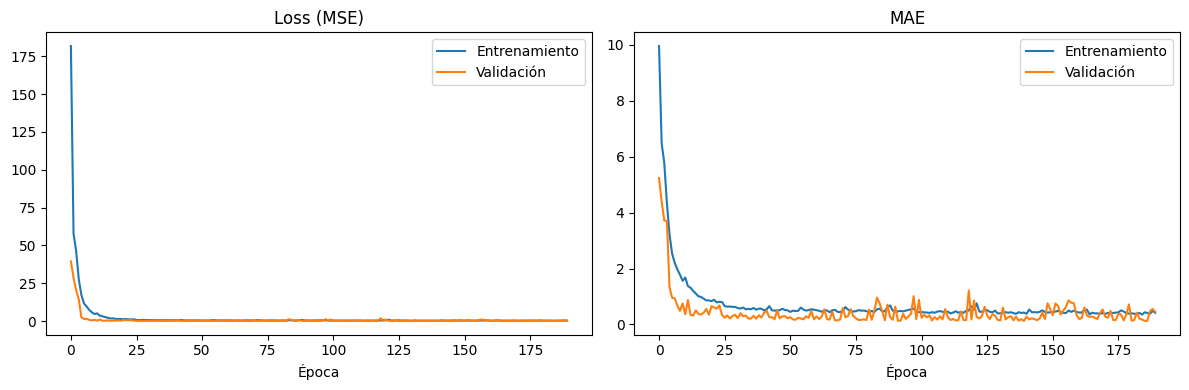

Loss (MSE, escala log): 0.0280
MAE (escala log): 0.1251
MAE en dólares reales: $20,921.01
RMSE en dólares reales: $29,740.56


In [100]:
if __name__ == "__main__":
    # se reforma la llamada al main()
    COLUMNAS_A_EXCLUIR = [
    'GarageArea',      # ya confirmado
    'TotalBsmtSF',     # ya confirmado
  ]
    resultados = main(columnas_a_excluir=COLUMNAS_A_EXCLUIR)
    #resultados = main()
    X_train = resultados['X_train']
    X_test = resultados['X_test']
    y_train_log = resultados['y_train_log']
    y_test_log = resultados['y_test_log']
    y_test_original = resultados['y_test_original']

    print(f"¿GarageArea sigue en X_train?: {'GarageArea' in resultados['X_train'].columns}")
    print(f"Número de columnas en X_train: {resultados['X_train'].shape[1]}")

    # Preguntar al usuario qué modo de entrenamiento usar
    modo = input("¿Qué modo de entrenamiento quieres usar? ('manual' / 'tuner'): ").strip().lower()

    while modo not in ('manual', 'tuner'):
        modo = input("Opción no válida. Escribe 'manual' o 'tuner': ").strip().lower()

    modelo, historia = ejecutar_entrenamiento(
        X_train, y_train_log, X_test, y_test_log, y_test_original,
        modo=modo
    )

In [93]:
import pandas as pd

def detectar_multicolinealidad(df, numerical_vars, target='SalePrice', umbral=0.70):

    corr_matrix = df[numerical_vars + [target]].corr()

    pares = []
    for i in range(len(numerical_vars)):
        for j in range(i + 1, len(numerical_vars)):
            col_i = numerical_vars[i]
            col_j = numerical_vars[j]
            valor = corr_matrix.loc[col_i, col_j]
            if abs(valor) > umbral:
                pares.append({
                    'Variable 1': col_i,
                    'Variable 2': col_j,
                    'Correlación (V1-V2)': round(valor, 3),
                    f'Corr. V1-{target}': round(corr_matrix.loc[col_i, target], 3),
                    f'Corr. V2-{target}': round(corr_matrix.loc[col_j, target], 3),
                })

    pares_df = pd.DataFrame(pares).sort_values('Correlación (V1-V2)', key=abs, ascending=False).reset_index(drop=True)
    return pares_df

In [95]:
config = obtener_configuracion_columnas()

df_corr = cargar_dataset('train.csv')
stats_corr = calcular_estadisticas_numericas(df_corr)
df_corr = limpiar_datos(df_corr, stats_corr, config['cols_to_impute_with_none'])
df_corr, _ = codificar_ordinales(df_corr, config['ordinal_cols'])

vars_a_analizar = config['numerical_vars'] + config['ordinal_cols']
vars_presentes = [c for c in vars_a_analizar if c in df_corr.columns]

pares_colineales_v2 = detectar_multicolinealidad(df_corr, vars_presentes, target='SalePrice', umbral=0.70)
display(pares_colineales_v2)

Imputando 'LotFrontage' con la Media (70.05) debido a media y mediana similares.
Imputando 'GarageYrBlt' con la Media (1978.51) debido a media y mediana similares.
Imputando 'MasVnrArea' con la Mediana (0) debido a Mediana=0 y Media>0.

Valores nulos restantes después de la imputación numérica:


'| Variable     |   Nulos Restantes (%) |\n|:-------------|----------------------:|\n| Alley        |            93.7671    |\n| MasVnrType   |            59.726     |\n| BsmtQual     |             2.53425   |\n| BsmtCond     |             2.53425   |\n| BsmtExposure |             2.60274   |\n| BsmtFinType1 |             2.53425   |\n| BsmtFinType2 |             2.60274   |\n| Electrical   |             0.0684932 |\n| FireplaceQu  |            47.2603    |\n| GarageType   |             5.54795   |\n| GarageFinish |             5.54795   |\n| GarageQual   |             5.54795   |\n| GarageCond   |             5.54795   |\n| PoolQC       |            99.5205    |\n| Fence        |            80.7534    |\n| MiscFeature  |            96.3014    |'

Columnas categóricas a imputar con 'None':
  - 'PoolQC': 1453 valores nulos imputados con 'None'.
  - 'MiscFeature': 1406 valores nulos imputados con 'None'.
  - 'Alley': 1369 valores nulos imputados con 'None'.
  - 'Fence': 1179 valores nulos imputados con 'None'.
  - 'MasVnrType': 872 valores nulos imputados con 'None'.
  - 'FireplaceQu': 690 valores nulos imputados con 'None'.
  - 'GarageType': 81 valores nulos imputados con 'None'.
  - 'GarageFinish': 81 valores nulos imputados con 'None'.
  - 'GarageQual': 81 valores nulos imputados con 'None'.
  - 'GarageCond': 81 valores nulos imputados con 'None'.
  - 'BsmtExposure': 38 valores nulos imputados con 'None'.
  - 'BsmtFinType2': 38 valores nulos imputados con 'None'.
  - 'BsmtQual': 37 valores nulos imputados con 'None'.
  - 'BsmtFinType1': 37 valores nulos imputados con 'None'.
  - 'BsmtCond': 37 valores nulos imputados con 'None'.

Verificando valores nulos restantes en columnas categóricas (excluyendo 'Electrical'):
La columna '

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LandContour,LotConfig,Neighborhood,...,HeatingQC,KitchenQual,Functional,FireplaceQu,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence
0,1,60,RL,65.0,8450,Pave,None,Lvl,Inside,CollgCr,...,4.0,3.0,7.0,0.0,2.0,3.0,3.0,2.0,0.0,0.0
1,2,20,RL,80.0,9600,Pave,None,Lvl,FR2,Veenker,...,4.0,2.0,7.0,3.0,2.0,3.0,3.0,2.0,0.0,0.0
2,3,60,RL,68.0,11250,Pave,None,Lvl,Inside,CollgCr,...,4.0,3.0,7.0,3.0,2.0,3.0,3.0,2.0,0.0,0.0
3,4,70,RL,60.0,9550,Pave,None,Lvl,Corner,Crawfor,...,3.0,3.0,7.0,4.0,1.0,3.0,3.0,2.0,0.0,0.0
4,5,60,RL,84.0,14260,Pave,None,Lvl,FR2,NoRidge,...,4.0,3.0,7.0,3.0,2.0,3.0,3.0,2.0,0.0,0.0


,Variable 1,Variable 2,Correlación (V1-V2),Corr. V1-SalePrice,Corr. V2-SalePrice
0,GarageQual,GarageCond,0.959,0.274,0.263
1,PoolArea,PoolQC,0.900,0.092,0.115
2,GarageCars,GarageArea,0.882,0.640,0.623
3,Fireplaces,FireplaceQu,0.863,0.467,0.520
4,GrLivArea,TotRmsAbvGrd,0.825,0.709,0.534
5,TotalBsmtSF,1stFlrSF,0.820,0.614,0.606
6,BsmtFinSF2,BsmtFinType2,0.789,-0.011,-0.005
7,YearBuilt,GarageYrBlt,0.781,0.523,0.470
8,OverallQual,ExterQual,0.726,0.791,0.683
9,ExterQual,KitchenQual,0.716,0.683,0.660


In [91]:
from sklearn.preprocessing import OrdinalEncoder

# Verificar el orden que asignaría el encoder a PoolQC
encoder_prueba = OrdinalEncoder()
encoder_prueba.fit(df[['PoolQC']])

print("Categorías de PoolQC, en el orden que les asignaría el encoder:")
for codigo, categoria in enumerate(encoder_prueba.categories_[0]):
    print(f"  Código {codigo} → '{categoria}'")

print()

# Verificar también KitchenQual, para confirmar el patrón
encoder_prueba2 = OrdinalEncoder()
encoder_prueba2.fit(df[['KitchenQual']])

print("Categorías de KitchenQual, en el orden que les asignaría el encoder:")
for codigo, categoria in enumerate(encoder_prueba2.categories_[0]):
    print(f"  Código {codigo} → '{categoria}'")

Categorías de PoolQC, en el orden que les asignaría el encoder:
  Código 0 → '0.0'
  Código 1 → '1.0'
  Código 2 → '2.0'
  Código 3 → '3.0'

Categorías de KitchenQual, en el orden que les asignaría el encoder:
  Código 0 → '0.0'
  Código 1 → '1.0'
  Código 2 → '2.0'
  Código 3 → '3.0'


## Variables Candidatas a Exclusión (Análisis de Multicolinealidad)

Basado en el análisis de mapas de calor de correlación (Grupos 1-4) realizado sobre las
variables numéricas del dataset, se identificaron los siguientes pares de variables con
alta colinealidad entre sí (correlación > 0.80), candidatas a revisión en iteraciones
posteriores del modelo.

### Par 1: GarageCars ↔ GarageArea
- **Correlación:** 0.88 (la más alta detectada en todo el análisis)
- **Correlación individual con SalePrice:** GarageCars = 0.64 | GarageArea = 0.62
- **Justificación de la redundancia:** Ambas variables capturan esencialmente la misma
  información — la capacidad/tamaño del garaje. Es lógico que coincidan: garajes con
  capacidad para más autos (GarageCars) tienden a tener mayor área física (GarageArea).
- **Candidata a eliminar (si se decide simplificar):** GarageArea, conservando GarageCars
  por ser una medida más directa e interpretable (capacidad en número de autos).

### Par 2: TotalBsmtSF ↔ 1stFlrSF
- **Correlación:** 0.82
- **Correlación individual con SalePrice:** TotalBsmtSF = 0.61 | 1stFlrSF = 0.61
- **Justificación de la redundancia:** En muchas viviendas, el área del sótano coincide
  aproximadamente con el área del primer piso construido directamente encima.
- **Candidata a eliminar (si se decide simplificar):** Ninguna con prioridad clara — ambas
  aportan la misma correlación con SalePrice; la decisión dependería de un análisis
  adicional (ej. importancia de variables tras entrenar un primer modelo).

### Decisión para el experimento base

Se decide **NO eliminar estas variables en la primera iteración del modelo**, por las
siguientes razones:

1. Ninguna correlación entre predictoras supera el umbral crítico de 0.90-0.95, considerado
   más determinante para justificar una eliminación automática.
2. Las correlaciones de ambos pares con la variable objetivo (SalePrice) son relevantes
   (>0.60), por lo que eliminar una variable sin evidencia empírica de perjuicio podría
   descartar información útil.
3. El modelo de red neuronal incorporará técnicas de regularización (Dropout, L1/L2 —
   Clase 5), que mitigan naturalmente el impacto de la multicolinealidad, a diferencia de
   modelos lineales clásicos.
4. Estas variables quedan documentadas como candidatas a exclusión en una **segunda
   iteración**, en caso de observarse overfitting severo o si se busca simplificar la
   arquitectura del modelo tras evaluar el desempeño del experimento base.